# Automated ML Pipeline

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.base import clone
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, LogisticRegression)
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor,
    RandomForestClassifier, GradientBoostingClassifier
)
from xgboost import XGBClassifier, XGBRegressor
from sklearn.dummy import DummyRegressor, DummyClassifier
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import RandomizedSearchCV
import json, joblib, sklearn
from datetime import datetime
from pathlib import Path
from sklearn.metrics import get_scorer

## Config code 
 

In [2]:
FILE_PATH = "../Data/Pipeline_data/Regression/house/train.csv"

if "_target_cache" not in globals():
    _target_cache = {'path': None, 'target': None, 'task': None}

def load_data(file_path):
    if not os.path.isfile(file_path):
        raise FileNotFoundError(f"File not found: {file_path}")
    return pd.read_csv(file_path, sep=None, engine='python')

def ask_target(df):
    print("Columns:",list(df.columns))
    while True:
        target = input("Enter the target column").strip()
        if target in df.columns:
            return target
        print(f"'{target}' not found. Try again.")

def get_target(df, file_path):
    if _target_cache['path'] == file_path and _target_cache['target'] in df.columns:
        print(f"Same file, reusing target: {_target_cache['target']}")
        return _target_cache['target']
    target = ask_target(df)
    _target_cache.update({'path': file_path, 'target': target, 'task': None})
    return  target

df = load_data(FILE_PATH)
TARGET = get_target(df, FILE_PATH)

Columns: ['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',

## Inspection 

In [3]:
def inspection(df):
    # checking the shape of data 
    print(f"rows: {df.shape[0]} \ncolumns: {df.shape[1]}\n")

    # checking for numerical and string columns
    num_col = df.select_dtypes(include='number').columns.tolist()
    string_col = df.select_dtypes(include=['object', 'string']).columns.tolist()
    print(f'Numerical Columns: {num_col} \nString Columns: {string_col}\n')

    # missing value percentage
    print('null values')
    percentage = (df.isna().mean() * 100).round(3).to_dict()
    null_pct = {col: pct for col, pct in percentage.items() if pct > 0}
    if not null_pct:
        print("Null Values: 0%\n")
    else:
        for col, pct in null_pct.items():
            print(f"{col}: {pct}%")
    print('')
    # Unique Value count per column
    unique_val = df[string_col].nunique().to_dict()
    for col, val in unique_val.items():
        print(f"{col} unique values: {val}") # \n here add new line after execution of for loop every time
    print('') # adds an empty line \n not used because it add 2 empty rows 
  
    # duplicate rows
    print(f"Duplicate rows: {df.duplicated().sum()}\n")

    # constant columns
    constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
    print(f"Constant columns: {constant_cols if constant_cols else 'None'}")

inspection(df)

rows: 1460 
columns: 81

Numerical Columns: ['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice'] 
String Columns: ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Fu

Target 'SalePrice' is numeric (int64)

count : 1460.0
mean : 180921.196
std : 79442.503
min : 34900.0
25% : 129975.0
50% : 163000.0
75% : 214000.0
max : 755000.0

Skewness of 'SalePrice': 1.883 (strongly skewed)


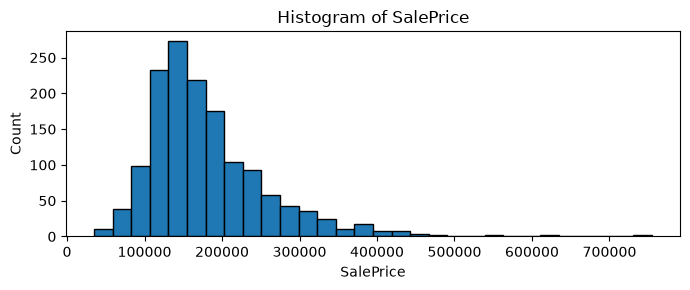

In [4]:
def target_check(df, target):
    # data type
    # this prints the data type of the target 
    kind = df[target].dtype.kind 
    if kind in 'iuf':
        print(f"Target '{target}' is numeric ({df[target].dtype})\n")
    elif kind in 'OU':
        print(f"Target '{target}' is string ({df[target].dtype})\n")
    else:
        print(f"Target '{target}' is non numeric ({df[target].dtype})\n")

    # describe the target 
    # this code store the values of describing the target to a dict with round value upto 3 
    if kind in 'iuf':
        desc_data = df[target].describe().round(3).to_dict()
        for desc, val in desc_data.items():
            print(f"{desc} : {val}")
        print('') # this only add an empty line 

    # first check if the target is numeric or not and the unique values
    if kind in 'iuf' and df[target].nunique() > 10:
        # skewness
        # this calculate the skewness of the target and tells if the target is how much skewed 
        skewness = df[target].skew()
        if abs(skewness) <=0.5:
            label = 'roughly symmetric'
        elif abs(skewness) <=1:
            label = 'moderately skewed'
        else:
            label = 'strongly skewed'
        print(f"Skewness of '{target}': {skewness:.3f} ({label})")

    # first check for numeric values
    if kind in 'iuf':
        fig, axes = plt.subplots(figsize=(7, 3))
        axes.hist(df[target].dropna(), bins=30, edgecolor='black')
        axes.set_title(f"Histogram of {target}")
        axes.set_xlabel(target)
        axes.set_ylabel("Count")
        plt.tight_layout()
        plt.show()
    else:
        print("Skipping plots: target is not numeric")

    # class counts for low-cardinality targets
    if kind in 'OUbiu' and df[target].nunique() <= 10:
        counts = df[target].value_counts()
        print(counts)
        print(f"\nImbalance ratio: {counts.max() / counts.min():.2f}")
        print(f"Min class size: {counts.min()}")
    

target_check(df, TARGET)

## Regression Or Classification

In [5]:
def confirm(message):
        return input(f"{message} Continue? (y/n):").strip().lower() == 'y'

def ask_task():
        while True:
                choice = input("Enter task type (r = regression, c = classification):").strip().lower()
                if choice in ('r', 'regression'):
                        return 'regression'
                if choice in ('c', 'classification'):
                        return 'classification'
                print(f"'{choice}' is invalid. Enter r or c")


def check_regression_choice(series, warn_unique):
        if series.dtype.kind not in 'iuf':
                print(f"Hard Warning: regression needs numeric target, but {series.name} is {series.dtype}")
                return False
        n_unique = series.nunique()
        if n_unique <= warn_unique:
                return confirm(f"SOFT WARNING: target has only {n_unique} unique values, which looks like classification.")
        return True

def check_classification_choice(series, warn_unique):
        if series.dtype.kind == 'f':
                if not confirm(f"SOFT WARNING: target is float ({series.dtype}), which looks like regression."):
                        return False
        if series.dtype.kind in 'iuf' and series.nunique() > warn_unique:
                return confirm(f"SOFT WARNING: target has {series.nunique()} unique values, which looks like regression.")
        return True

def get_task_type(df, target, warn_unique = 10):
        if _target_cache['task'] is not None:
                print(f"Same file and target, reusing the task type : {_target_cache['task']}")
                return _target_cache['task']
        series = df[target]
        while True:
                task = ask_task()
                if task == 'regression' and not check_regression_choice(series, warn_unique):
                        continue
                if task == 'classification' and not check_classification_choice(series, warn_unique):
                        continue

                _target_cache['task'] = task
                print(f"Task type set: {task}")
                return task

TASK = get_task_type(df, TARGET)

Task type set: regression


## Cleaning the data

In [6]:
def clean_data(df, target, missing_thresh = 0.5, id_ratio = 0.95):
    df = df.copy()
    report = {"initial_shape": df.shape}

    # drop rows with missing targets
    n = len(df)
    df = df.dropna(subset= [target])
    report['rows_dropped_missing_target'] = n - len(df)

    # drop duplicate rows
    n = len(df)
    df = df.drop_duplicates()
    report['duplicated_rows_dropped'] = n - len(df)

    feats = [c for c in df.columns if c != target]
    
    # drop constant columns
    constant_cols = [c for c in feats if df[c].nunique(dropna=False) <= 1]
    df = df.drop(columns=constant_cols)
    report['constant_cols'] = constant_cols
    feats = [c for c in feats if c not in constant_cols]

    # drop column missing the threshold 
    high_missing_cols = [c for c in feats if df[c].isna().mean() > missing_thresh]
    df = df.drop(columns= high_missing_cols)
    report['high_missing_col'] = high_missing_cols
    feats = [c for c in feats if c not in high_missing_cols]

    # drop id-like columns
    id_cols = [
        c for c in feats
        if df[c].dtype.kind != 'f' and df[c].nunique() / len(df) >= id_ratio
    ]
    df = df.drop(columns = id_cols)
    report['drop_id_like_columns'] = id_cols
    feats = [c for c in feats if c not in id_cols]

    # drop duplicate columns
    dup_mask = df[feats].T.duplicated()
    dup_cols = dup_mask[dup_mask].index.tolist()
    df = df.drop(columns = dup_cols)
    report['duplicated_columns'] = dup_cols

    # final report
    report["final_shape"] = df.shape
    return df, report

df_clean, clean_report = clean_data(df, TARGET)
clean_report

{'initial_shape': (1460, 81),
 'rows_dropped_missing_target': 0,
 'duplicated_rows_dropped': 0,
 'constant_cols': [],
 'high_missing_col': ['Alley', 'MasVnrType', 'PoolQC', 'Fence', 'MiscFeature'],
 'drop_id_like_columns': ['Id'],
 'duplicated_columns': [],
 'final_shape': (1460, 75)}

## Splitting

In [7]:
TEST_SIZE = 0.2
RANDOM_STATE = 42
N_SPLITS = 5

CLASS_NAMES = None
if TASK == 'classification':
    counts = df_clean[TARGET].value_counts()
    print(counts, f"\nImbalance ratio: {counts.max() / counts.min():.2f}")
    if counts.min() < 2:
        raise ValueError(f"Classes with fewer than 2 samples: {counts[counts < 2].to_dict()}")
    le = LabelEncoder()
    y = pd.Series(le.fit_transform(df_clean[TARGET]), index=df_clean.index, name=TARGET)
    CLASS_NAMES = le.classes_.tolist()
else:
    y = df_clean[TARGET]

X = df_clean.drop(columns=TARGET)
stratify = y if TASK == 'classification' else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=stratify
)

if TASK == 'classification':
    train_counts = y_train.value_counts()
    rare = train_counts[train_counts < N_SPLITS]
    if not rare.empty:
        raise ValueError(
            f"Classes with fewer than {N_SPLITS} train samples (CV needs >= {N_SPLITS}): "
            f"{ {CLASS_NAMES[i]: int(n) for i, n in rare.items()} }"
        )

## Encoding

In [8]:

def build_preprocessor(df, num_strategy='median', add_indicator=True, use_scaler=True, cat_strategy='most_frequent'):
    numeric_col = df.select_dtypes(include='number').columns.to_list()
    string_col = df.select_dtypes(include=['string', 'object', 'category', 'bool']).columns.to_list()
    dropped_col = [c for c in df.columns if c not in numeric_col + string_col]
    if dropped_col:
        print(f"WARNING: unsupported dtypes, dropped from model: {dropped_col}")

    nums_steps = [('imputer', SimpleImputer(strategy=num_strategy, add_indicator=add_indicator))]
    if use_scaler:
        nums_steps.append(('scaler', StandardScaler()))

    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy=cat_strategy)),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])

    preprocessor = ColumnTransformer([
        ('num', Pipeline(nums_steps), numeric_col),
        ('cat', cat_pipe, string_col),
    ], remainder='drop')
    return preprocessor, numeric_col, string_col, dropped_col

preprocessor, numeric_col, string_col, dropped_col = build_preprocessor(X_train)

X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)

print(f"Numeric cols: {len(numeric_col)} | Categorical cols: {len(string_col)}")
print(f"Train shape: {X_train_t.shape} | Test shape: {X_test_t.shape}")
print(f"Leftover NaNs -> train: {np.isnan(X_train_t).sum()}, test: {np.isnan(X_test_t).sum()}")

Numeric cols: 36 | Categorical cols: 38
Train shape: (1168, 272) | Test shape: (292, 272)
Leftover NaNs -> train: 0, test: 0


## Model

In [9]:
TREE_SPACES = {
    'RandomForest': {
        'n_estimators': randint(100, 500),
        'max_depth': randint(3, 20),
        'min_samples_split': randint(2, 20),
        'min_samples_leaf': randint(1, 10),
        'max_features': uniform(0.3, 0.7),
    },
    'GradientBoosting': {
        'n_estimators': randint(100, 500),
        'learning_rate': loguniform(0.01, 0.3),
        'max_depth': randint(2, 6),
        'subsample': uniform(0.6, 0.4),
        'min_samples_leaf': randint(1, 10),
    },
    'XGBoost': {
        'n_estimators': randint(100, 500),
        'learning_rate': loguniform(0.01, 0.3),
        'max_depth': randint(2, 8),
        'subsample': uniform(0.6, 0.4),
        'colsample_bytree': uniform(0.6, 0.4),
        'reg_lambda': loguniform(0.01, 10),
    },
}

In [10]:
TASK_CONFIG = {
    'regression':{
        'baseline': DummyRegressor(strategy= 'mean'),
        'primary_metric':'RMSE',
        'ascending': True,
        'models':{
            'Linear': LinearRegression(),
            'Ridge': Ridge(random_state= RANDOM_STATE),
            'Lasso': Lasso(random_state= RANDOM_STATE),
            'RandomForest': RandomForestRegressor(random_state= RANDOM_STATE),
            'GradientBoosting': GradientBoostingRegressor(random_state= RANDOM_STATE),
            'XGBoost': XGBRegressor(random_state=RANDOM_STATE, n_jobs=1),
        },
        'cv': KFold(n_splits= N_SPLITS,shuffle= True, random_state= RANDOM_STATE),
        'metrics': {
            'RMSE': 'neg_root_mean_squared_error',
            'MAE': 'neg_mean_absolute_error',
            'R2': 'r2',
        },
        'search_spaces': {
            'Ridge': {'alpha': loguniform(1e-3, 1e2)},
            'Lasso': {'alpha': loguniform(1e-4, 1e1)},
            **TREE_SPACES,
        },
    },

    'classification': {
        'baseline': DummyClassifier(strategy= 'most_frequent'),
        'primary_metric': 'F1',
        'ascending': False,
        'models': {
            'Logistic': LogisticRegression(max_iter= 1000, random_state= RANDOM_STATE),
            'RandomForest': RandomForestClassifier(random_state= RANDOM_STATE),
            'GradientBoosting': GradientBoostingClassifier(random_state= RANDOM_STATE),
            'XGBoost': XGBClassifier(random_state = RANDOM_STATE,n_jobs=1),
        },
        'cv': StratifiedKFold(n_splits= N_SPLITS, shuffle= True, random_state= RANDOM_STATE),
        'metrics':{
            'Accuracy': 'accuracy',
            'F1': 'f1_weighted',
            'ROC_AUC': 'roc_auc_ovr',
        },
        'search_spaces':{
            'Logistic': {'C': loguniform(1e-3, 1e2)},
            **TREE_SPACES,
        },
    },
}

def build_model_pipeline(task, preprocessor):
    pipeline = {
        'Baseline':Pipeline([
            ('preprocessor', clone(preprocessor)),
            ('model', clone(TASK_CONFIG[task]['baseline'])),
        ])
    }
    for name, model in TASK_CONFIG[ task]['models'].items():
        pipeline[name] = Pipeline([
            ('preprocessor',clone(preprocessor)),
            ('model', clone(model)),
        ])
    return pipeline

model_pipelines = build_model_pipeline(TASK, preprocessor)
print(f"Task: {TASK} | Models: {list(model_pipelines.keys())}")

Task: regression | Models: ['Baseline', 'Linear', 'Ridge', 'Lasso', 'RandomForest', 'GradientBoosting', 'XGBoost']


In [11]:
def benchmark_models(task, pipeline, X, y):
    cv = TASK_CONFIG[task]['cv']
    metrics = TASK_CONFIG[task]['metrics']
    rows, error = [], {}
    for name, pipe in pipeline.items():
        try:
            res = cross_validate(
                pipe, X, y,
                cv = cv, scoring= metrics, error_score= 'raise', n_jobs= -1
            )
            row = {'Model': name}
            for metric in metrics:
                scores = res[f'test_{metric}']
                if metric in ('RMSE', 'MAE'):
                    scores = -scores
                row[f'{metric}_mean'] = scores.mean()
                row[f'{metric}_std'] = scores.std()
            row['Fit_time_s'] = res['fit_time'].mean()
            rows.append(row)
        except Exception as e:
            error[name] = str(e)
            print(f"Failed: {name} -> {e}")
    return pd.DataFrame(rows), error

benchmark_df, benchmark_errors = benchmark_models(TASK, model_pipelines, X_train, y_train)
benchmark_df.round(4)

/home/harsh/Work/.venv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.636403e+10, tolerance: 5.386e+08
  model = cd_fast.enet_coordinate_descent(
/home/harsh/Work/.venv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.587376e+09, tolerance: 5.453e+08
  model = cd_fast.enet_coordinate_descent(
/home/harsh/Work/.venv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation.

,Model,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,Fit_time_s
0,Baseline,77160.1085,3673.2528,56318.2323,2612.1485,-0.0016,0.0013,0.0379
1,Linear,35786.3438,7634.0695,19490.4674,887.2536,0.7771,0.0830,0.0380
2,Ridge,32669.5223,7312.3153,18816.2199,992.2347,0.8164,0.0711,0.0274
3,Lasso,35288.3257,7508.7909,19127.0270,909.5278,0.7835,0.0805,0.0901
4,RandomForest,30611.0138,5040.2177,18219.7551,1130.8668,0.8405,0.0433,1.0422
5,GradientBoosting,27669.0296,6117.1602,15972.9497,1503.1369,0.8672,0.0535,0.4328
6,XGBoost,30582.3348,6586.3543,17835.0602,972.1427,0.8397,0.0600,0.5034


In [12]:
def build_scoreboard(task, benchmark_df, errors):
    pm = TASK_CONFIG[task]['primary_metric']
    asc = TASK_CONFIG[task]['ascending']
    mean_col, std_col = f'{pm}_mean', f"{pm}_std"

    sb = benchmark_df.sort_values(mean_col, ascending = asc).reset_index(drop = True)
    sb.insert(0, 'Rank', sb.index + 1)

    base = sb.loc[sb['Model'] == 'Baseline', mean_col].iloc[0]
    if asc:
        sb['Improvement_vs_baseline_%'] = (base - sb[mean_col])/ base * 100
    else:
        sb['Improvement_vs_baseline_%'] = (sb[mean_col] - base) / base * 100

    best_mean, best_std = sb.loc[0, mean_col], sb.loc[0, std_col]
    sb['Tied_with_best'] = (sb[mean_col] - best_mean).abs() <= best_std

    if errors:
        print('Failed Models:')
        for name, msg in errors.items():
            print(f"{name}:{msg}")
    return sb
scoreboard = build_scoreboard(TASK, benchmark_df, benchmark_errors)
scoreboard.round(4)

,Rank,Model,RMSE_mean,RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,Fit_time_s,Improvement_vs_baseline_%,Tied_with_best
0,1,GradientBoosting,27669.0296,6117.1602,15972.9497,1503.1369,0.8672,0.0535,0.4328,64.1408,True
1,2,XGBoost,30582.3348,6586.3543,17835.0602,972.1427,0.8397,0.0600,0.5034,60.3651,True
2,3,RandomForest,30611.0138,5040.2177,18219.7551,1130.8668,0.8405,0.0433,1.0422,60.3279,True
3,4,Ridge,32669.5223,7312.3153,18816.2199,992.2347,0.8164,0.0711,0.0274,57.6601,True
4,5,Lasso,35288.3257,7508.7909,19127.0270,909.5278,0.7835,0.0805,0.0901,54.2661,False
5,6,Linear,35786.3438,7634.0695,19490.4674,887.2536,0.7771,0.0830,0.0380,53.6207,False
6,7,Baseline,77160.1085,3673.2528,56318.2323,2612.1485,-0.0016,0.0013,0.0379,0.0000,False


In [13]:
def tune_top_k(task, scoreboard, pipelines, X, y, k=3, n_iter=30):
    cfg = TASK_CONFIG[task]
    pm = cfg['primary_metric']
    scoring = cfg['metrics'][pm]
    negated = scoring.startswith('neg_')
    asc = cfg['ascending']

    candidates = scoreboard.loc[scoreboard['Model'] != 'Baseline', 'Model'].head(k).tolist()
    rows, best_estimators, errors = [], {}, {}

    for name in candidates:
        untuned = scoreboard.loc[scoreboard['Model'] == name, f'{pm}_mean'].iloc[0]
        try:
            space = cfg['search_spaces'].get(name)
            tuned, params, est = np.nan, {}, None
            if space:
                search = RandomizedSearchCV(
                    pipelines[name],
                    {f'model__{p}': d for p, d in space.items()},
                    n_iter=n_iter, scoring=scoring, cv=cfg['cv'],
                    random_state=RANDOM_STATE, n_jobs=-1,
                    refit=True, error_score='raise',
                )
                search.fit(X, y)
                tuned = -search.best_score_ if negated else search.best_score_
                params = {p.removeprefix('model__'): v for p, v in search.best_params_.items()}
                est = search.best_estimator_

            use_tuned = est is not None and ((tuned < untuned) if asc else (tuned > untuned))
            if not use_tuned:
                est, params = clone(pipelines[name]).fit(X, y), {}

            rows.append({
                'Model': name,
                f'Untuned_{pm}': untuned,
                f'Tuned_{pm}': tuned,
                f'Final_{pm}': tuned if use_tuned else untuned,
                'Selected': 'tuned' if use_tuned else 'untuned',
                'Best_params': params,
            })
            best_estimators[name] = est
        except Exception as e:
            errors[name] = str(e)
            print(f"Failed: {name} -> {e}")

    results = pd.DataFrame(rows).sort_values(f'Final_{pm}', ascending=asc).reset_index(drop=True)
    return results, best_estimators, errors

tuning_df, tuned_models, tuning_errors = tune_top_k(TASK, scoreboard, model_pipelines, X_train, y_train)
tuning_df

,Model,Untuned_RMSE,Tuned_RMSE,Final_RMSE,Selected,Best_params
0,XGBoost,30582.334766,25844.531641,25844.531641,tuned,"{'colsample_bytree': 0.7088528997538541, 'lear..."
1,GradientBoosting,27669.029620,26691.623805,26691.623805,tuned,"{'learning_rate': 0.03896217029789141, 'max_de..."
2,RandomForest,30611.013843,29525.937155,29525.937155,tuned,"{'max_depth': 17, 'max_features': 0.4213552574..."


In [16]:
def final_evaluation(task, tuning_df, tuned_models, pipelines, X_train, y_train, X_test, y_test):
    cfg = TASK_CONFIG[task]
    best_name = tuning_df.loc[0, 'Model']
    best_model = tuned_models[best_name]

    baseline = clone(pipelines['Baseline']).fit(X_train, y_train)

    def test_scores(est):
        out = {}
        for m, s in cfg['metrics'].items():
            val = get_scorer(s)(est, X_test, y_test)
            out[m] = -val if s.startswith('neg_') else val
        return out

    best_scores = test_scores(best_model)
    base_scores = test_scores(baseline)
    result = pd.DataFrame({'Baseline': base_scores, best_name: best_scores}).T
    return best_name, best_model, best_scores, result


def _jsonable(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


def save_artifact(task, target, best_name, best_model, best_scores, tuning_df, X_train,
                  class_names=None, out_dir='artifacts'):
    Path(out_dir).mkdir(exist_ok=True)
    joblib.dump(best_model, f'{out_dir}/model.joblib')
    row = tuning_df.loc[tuning_df['Model'] == best_name].iloc[0]
    metadata = {
        'task': task,
        'target': target,
        'model': best_name,
        'selected': row['Selected'],
        'primary_metric': TASK_CONFIG[task]['primary_metric'],
        'test_scores': best_scores,
        'best_params': row['Best_params'],
        'class_names': class_names,
        'features': X_train.columns.tolist(),
        'random_state': RANDOM_STATE,
        'sklearn_version': sklearn.__version__,
        'saved_at': datetime.now().isoformat(timespec='seconds'),
    }
    with open(f'{out_dir}/metadata.json', 'w') as f:
        json.dump(metadata, f, indent=2, default=_jsonable)


best_name, best_model, best_scores, final_df = final_evaluation(
    TASK, tuning_df, tuned_models, model_pipelines, X_train, y_train, X_test, y_test
)
save_artifact(TASK, TARGET, best_name, best_model, best_scores, tuning_df, X_train, CLASS_NAMES)
final_df.round(4)

,RMSE,MAE,R2
Baseline,87619.0345,62575.9265,-0.0009
XGBoost,26083.4688,16779.9551,0.9113
